<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 1: Import and explore the data (EDA)</h1>

<p>Each row of train.csv is one purchase. The target repeat_purchase_90d is 1 if the same customer buys again within 90 days and 0 if not.
</p>

<p>In this notebook we only explore the data and do not change anything yet. Everything we find goes into Task 2. We do not load test.csv
here so that it does not influence our decisions.</p>

<h2>Contents</h2>

<ol>
  <li><a href="#setup">Setup and import</a></li>
  <li><a href="#vars">Observations and variables</a></li>
  <li><a href="#target">The target</a></li>
  <li><a href="#desc">Descriptive statistics</a></li>
  <li><a href="#quality">Data quality</a></li>
  <li><a href="#clientes">clientes.csv</a></li>
  <li><a href="#uni">Univariate distributions</a></li>
  <li><a href="#bi">Relationship with the target</a></li>
  <li><a href="#multi">Multivariate relationships</a></li>
  <li><a href="#time">Changes over time</a></li>
  <li><a href="#summary">Summary and next Steps</a></li>
</ol>

</div>

<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and import</h2>

</div>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")

TARGET = "repeat_purchase_90d"

In [4]:
train = pd.read_csv("../data/train.csv")
clientes = pd.read_csv("../data/clientes.csv")

print("train:", train.shape)
print("clientes:", clientes.shape)

train: (6534, 39)
clientes: (1143, 13)


In [5]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Train has 6,534 rows and 39 columns (ID, target and 37 features)</li>
  <li>Clientes has 1,143 customers and 13 columns, we can join it with customer_id</li>
</ul>

</div>

<a id="vars"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. Observations and variables</h2>

<h3>2.1 What is one row</h3>

</div>

In [6]:
# is the ID unique?
print("duplicated IDs:", train["ID"].duplicated().sum())

# how many rows per customer
rows_per_customer = train.groupby("customer_id").size()
print("customers:", train["customer_id"].nunique())
print("customers with only 1 row:", (rows_per_customer == 1).sum())
rows_per_customer.describe()

duplicated IDs: 0
customers: 610
customers with only 1 row: 157


count    610.000000
mean      10.711475
std       19.969320
min        1.000000
25%        1.000000
50%        4.000000
75%       12.000000
max      277.000000
dtype: float64

In [7]:
# share of rows from the 10 biggest customers
print(rows_per_customer.sort_values(ascending=False).head(10).sum() / len(train))

# time period of the data
train["purchase_date"] = pd.to_datetime(train["purchase_date"])
print(train["purchase_date"].min(), train["purchase_date"].max())

0.17523722069176614
2015-07-11 00:00:00 2025-02-15 00:00:00


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>One row is one purchase but there are only <b>610 customers</b>, so every customer has around <b>10 rows on average</b> (max 277)</li>
  <li>The <b>10 biggest customers</b> have about <b>17.5% of all rows</b></li>
  <li><b>Rows of the same customer are not independent.</b> If we split randomly the same customer can be in train and validation, so later we should <b>split by customer or by time</b></li>
  <li>The data goes from <b>July 2015 to February 2025</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>2.2 Variables</h3>

<p>Some columns keep their Portuguese names from the original invoice data. To make them easier to work with, we put them into groups based on their meaning.</p>

</div>

In [8]:
INVOICE = ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
           "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes",
           "invoice_count_current_purchase"]
HISTORY = ["days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count",
           "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
           "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days",
           "prior_std_gap_days"]
WINDOWS = ["purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
           "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d"]
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method",
               "warehouse", "document_series"]
IDENTIFIERS = ["ID", "customer_id"]
NUMERIC = INVOICE + HISTORY + WINDOWS

print("invoice:", len(INVOICE), " history:", len(HISTORY), " windows:", len(WINDOWS),
      " categorical:", len(CATEGORICAL))

invoice: 10  history: 10  windows: 8  categorical: 6


In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Total a Pagar                   6469 non-null   float64       
 1   Total Bruto                     6469 non-null   float64       
 2   Total Liquido                   6469 non-null   float64       
 3   Total Imp_                      6469 non-null   float64       
 4   Total Portes                    6469 non-null   float64       
 5   Total Desc_ Global              6469 non-null   float64       
 6   Total Desc_ Linha               6469 non-null   float64       
 7   Custo                           6469 non-null   float64       
 8   N_ Detalhes                     6469 non-null   float64       
 9   invoice_count_current_purchase  6469 non-null   float64       
 10  repeat_purchase_90d             6534 non-null   int64         
 11  days_since_prev

In [10]:
# number of levels and % missing for every column
group = {}
for col in INVOICE: group[col] = "invoice"
for col in HISTORY: group[col] = "history"
for col in WINDOWS: group[col] = "windows"
for col in CATEGORICAL: group[col] = "categorical"

pd.DataFrame({
    "group": [group.get(col, "other") for col in train.columns],
    "dtype": train.dtypes.astype(str).values,
    "levels": train.nunique().values,
    "% missing": (100 * train.isna().mean()).round(2).values,
}, index=train.columns).sort_values("group")

,group,dtype,levels,% missing
document_series,categorical,str,3,0.99
warehouse,categorical,str,2,3.98
transport_method,categorical,str,80,3.99
commercial_zone,categorical,str,5,0.99
salesperson,categorical,str,9,3.96
payment_type,categorical,str,9,3.98
prior_mean_gap_days,history,float64,3874,20.02
prior_std_gap_days,history,float64,4911,22.62
prior_max_purchase_value,history,float64,1156,10.22
prior_min_purchase_value,history,float64,1157,10.22


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>The columns fall into <b>four groups</b>: the current invoice, the earlier purchases of the customer (history), purchases and spend in the 30 to 365 days before (windows), and the categorical codes. The rest are ID, customer_id, purchase_date, random_noise and the target</li>
  <li>The categories only have anonymous names like "Maybe Tomorrow Payment 7", so we <b>can't tell what they mean</b> from the name</li>
  <li>All numeric columns are stored as <b>float</b>, also count columns like N_ Detalhes or prior_purchase_count</li>
  <li>Almost every column has about <b>1% missing</b>, but some history columns have <b>up to 22%</b> </li>
</ul>

</div>

<a id="target"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. The target</h2>

</div>

In [11]:
print(train[TARGET].value_counts())
print(train[TARGET].value_counts(normalize=True))

repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64
repeat_purchase_90d
1    0.559229
0    0.440771
Name: proportion, dtype: float64


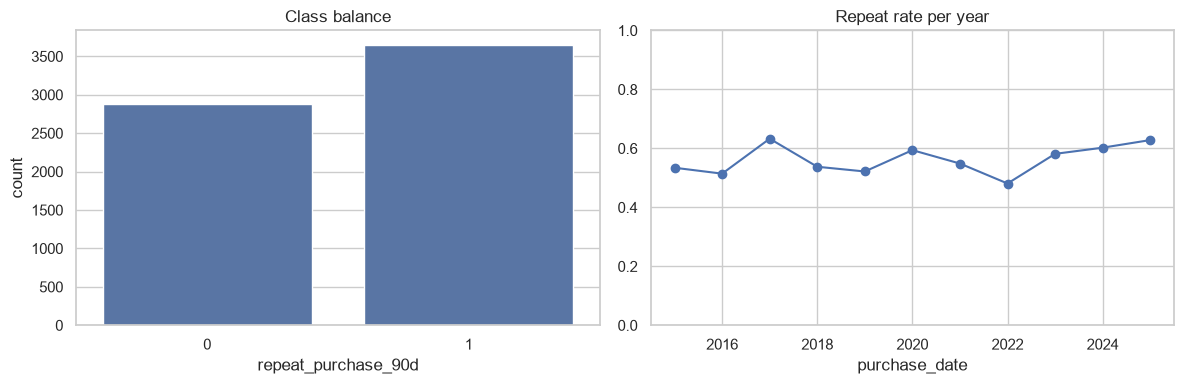

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=train[TARGET], ax=axes[0])
axes[0].set_title("Class balance")

# repeat rate per year
rate_per_year = train.groupby(train["purchase_date"].dt.year)[TARGET].mean()
rate_per_year.plot(marker="o", ax=axes[1])
axes[1].set_title("Repeat rate per year")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [13]:
train["purchase_date"].dt.year.value_counts().sort_index()

purchase_date
2015.0    335
2016.0    420
2017.0    670
2018.0    716
2019.0    646
2020.0    670
2021.0    782
2022.0    628
2023.0    767
2024.0    757
2025.0     78
Name: count, dtype: int64

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
<li>55.9% repeat and 44.1% no repeat, so the classes are only a bit imbalanced</li>
<li>Always predicting 1 would already be right in <b>55.9%</b> of the cases --> accuracy alone is not very meaningful here </li>
<li>The repeat rate per year is between about 0.48 and 0.63 with no clear trend --> 2025 has only 78 rows because the data stops in February</li>
</ul>

</div>

<a id="desc"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Descriptive statistics</h2>

<h3>4.1 Numeric variables</h3>

</div>

In [14]:
num = train[NUMERIC + ["random_noise"]]

desc = num.describe().T
desc["mean/median"] = desc["mean"] / desc["50%"].replace(0, np.nan)
desc["skew"] = num.skew()
# share of zeros among the values that are not missing
desc["% zeros"] = 100 * (num == 0).sum() / num.count()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,mean/median,skew,% zeros
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04,1.94,4.21,0.00
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04,1.99,4.31,0.00
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04,1.98,4.15,0.00
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03,1.91,4.84,3.29
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02,NaN,19.55,83.72
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02,NaN,27.46,98.30
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03,8.57,5.92,37.73
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03,2.15,4.61,7.51
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02,1.96,2.98,0.00
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00,1.07,6.44,0.00


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Most amount columns are <b>very right skewed</b> (skew 4 to 6) and the mean is about <b>2x the median</b> --> e.g. Total a Pagar has a mean of 926 but a median of only 477 --> the median describes a normal purchase better, and a log transform could help in Task 2</li>
  <li>Some columns are <b>mostly zero</b>, like Total Desc_ Global (98%) and Total Portes (84%)</li>
  <li>prior_mean_purchase_value and spend_365d have a max of <b>1,000,000,000</b> and also negative values, and two day columns go down to <b>-4</b> --> these values are not possible</li>
  <li>Because of these values the mean of prior_mean_purchase_value is about <b>2.8 million</b> while the median is only 725, so the mean is useless here</li>
  <li>random_noise has a mean of about 0 and a std of about 1 --> it really is just noise</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.2 Categorical variables</h3>

</div>

In [15]:
for col in CATEGORICAL:
    print(col, "- levels:", train[col].nunique(), "- missing:", train[col].isna().sum())

payment_type - levels: 9 - missing: 260
salesperson - levels: 9 - missing: 259
commercial_zone - levels: 5 - missing: 65
transport_method - levels: 80 - missing: 261
warehouse - levels: 2 - missing: 260
document_series - levels: 3 - missing: 65


In [16]:
for col in ["payment_type", "salesperson", "commercial_zone", "warehouse", "document_series"]:
    print(train[col].value_counts(normalize=True).round(3), "\n")

payment_type
Maybe Tomorrow Payment 7     0.728
Maybe Tomorrow Payment 12    0.158
Maybe Tomorrow Payment 9     0.080
Maybe Tomorrow Payment 10    0.021
Maybe Tomorrow Payment 8     0.006
Maybe Tomorrow Payment 2     0.003
Maybe Tomorrow Payment 4     0.001
Maybe Tomorrow Payment 11    0.001
Maybe Tomorrow Payment 3     0.001
Name: proportion, dtype: float64 

salesperson
VLOOKUP Master 1    0.646
VLOOKUP Master 4    0.233
VLOOKUP Master 9    0.061
VLOOKUP Master 7    0.032
VLOOKUP Master 2    0.020
VLOOKUP Master 3    0.005
VLOOKUP Master 6    0.002
VLOOKUP Master 5    0.001
VLOOKUP Master 8    0.000
Name: proportion, dtype: float64 

commercial_zone
Decorative Dashboard Zone 4    0.968
Decorative Dashboard Zone 2    0.023
Decorative Dashboard Zone 3    0.009
Decorative Dashboard Zone 6    0.000
Decorative Dashboard Zone 7    0.000
Name: proportion, dtype: float64 

warehouse
Final Excel Warehouse 1    0.997
Final Excel Warehouse 3    0.003
Name: proportion, dtype: float64 

document_

In [17]:
# transport_method has many levels, how many are rare?
transport_counts = train["transport_method"].value_counts()
print("levels with less than 30 rows:", (transport_counts < 30).sum())
transport_counts.head(10)

levels with less than 30 rows: 51


transport_method
Maybe Tomorrow Delivery 72    1119
Maybe Tomorrow Delivery 61     627
Maybe Tomorrow Delivery 73     445
Maybe Tomorrow Delivery 59     373
Maybe Tomorrow Delivery 80     319
Maybe Tomorrow Delivery 71     301
Maybe Tomorrow Delivery 40     257
Maybe Tomorrow Delivery 11     253
Maybe Tomorrow Delivery 53     247
Maybe Tomorrow Delivery 47     222
Name: count, dtype: int64

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Most categorical columns have <b>one big level</b> --> commercial_zone is <b>97% Zone 4</b> and warehouse <b>99.7% Warehouse 1</b>, so these two are almost constant</li>
  <li>transport_method has <b>80 levels</b> and <b>51 of them have less than 30 rows</b></li> <li> One-hot encoding would give 80 columns --> we need to <b>group the rare levels in Task 2</b></li>
  <li>payment_type, salesperson, transport_method and warehouse have about <b>260 missing values</b> each (out of 6,534 rows), commercial_zone and document_series only <b>65</b></li>
</ul>

</div>

<a id="quality"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Data quality</h2>

<h3>5.1 Empty rows</h3>

</div>

In [18]:
# all columns except ID, customer_id and target 
feature_cols = [c for c in train.columns if c not in IDENTIFIERS + [TARGET]]

# rows where all of these columns are missing
empty_rows = train[feature_cols].isna().all(axis=1)

print("completely empty rows:", empty_rows.sum())
print("repeat rate of these rows:", train.loc[empty_rows, TARGET].mean())

completely empty rows: 65
repeat rate of these rows: 0.5076923076923077


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>65 rows have no features at all, only ID, customer_id and target</li>
  <li>Their repeat rate is about the same as overall, so there is nothing to learn from them --> we can drop them in Task 2</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.2 Duplicates</h3>

</div>

In [19]:
print("duplicates:", train.duplicated().sum())
print("duplicates without ID:", train.drop(columns="ID").duplicated().sum())

# for the rest we work without the empty rows
tr = train[~empty_rows].copy()
print("duplicates without ID and without empty rows:", tr.drop(columns="ID").duplicated().sum())
print("same customer on the same day:", tr.duplicated(subset=["customer_id", "purchase_date"]).sum())

duplicates: 0
duplicates without ID: 10
duplicates without ID and without empty rows: 0
same customer on the same day: 0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>There are <b>no real duplicates</b>
  <li>The 10 we find without ID are only empty rows of the same customer</li>
  <li>No customer has <b>two rows on the same day</b> --> so every row is a separate purchase and nothing was recorded twice</li>
    
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.3 Missing values</h3>

</div>

In [20]:
missing = tr.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "%": (100 * missing / len(tr)).round(2)})

,missing,%
prior_std_gap_days,1413,21.84
prior_mean_gap_days,1243,19.21
prior_std_purchase_value,1048,16.20
prior_mean_purchase_value,797,12.32
days_since_previous_purchase,796,12.30
prior_min_purchase_value,603,9.32
prior_max_purchase_value,603,9.32
transport_method,196,3.03
spend_365d,195,3.01
payment_type,195,3.01


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Many history values should be <b>missing on purpose</b>. For example a first purchase has no previous purchase, so there are no days since the last one --> we check this by the number of earlier purchases</p>

</div>

In [21]:
# 0, 1, 2 or 3+ earlier purchases
prior_group = tr["prior_purchase_count"].clip(upper=3)

history_cols = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                "prior_mean_gap_days", "prior_std_gap_days", "spend_365d"]
tr[history_cols].isna().groupby(prior_group).mean().T.round(3)

prior_purchase_count,0.0,1.0,2.0,3.0
days_since_previous_purchase,1.00,0.043,0.055,0.030
prior_mean_purchase_value,1.00,0.045,0.030,0.032
prior_std_purchase_value,1.00,1.000,0.000,0.000
prior_mean_gap_days,1.00,1.000,0.058,0.034
prior_std_gap_days,1.00,1.000,1.000,0.000
spend_365d,0.03,0.043,0.041,0.028


In [22]:
# do first purchases repeat less often?
first = tr["prior_purchase_count"] == 0
print("repeat rate first purchase:", tr.loc[first, TARGET].mean().round(3))
print("repeat rate other purchases:", tr.loc[~first, TARGET].mean().round(3))

# do rows with a missing value repeat more or less often?
for col in ["payment_type", "salesperson", "transport_method", "spend_365d"]:
    print(col, "missing:", tr.loc[tr[col].isna(), TARGET].mean().round(3),
          " not missing:", tr.loc[tr[col].notna(), TARGET].mean().round(3))

repeat rate first purchase: 0.333
repeat rate other purchases: 0.583
payment_type missing: 0.564  not missing: 0.56
salesperson missing: 0.598  not missing: 0.559
transport_method missing: 0.551  not missing: 0.56
spend_365d missing: 0.564  not missing: 0.56


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Most missing history values <b>make sense</b> --> with 0 earlier purchases all history values are missing, with 1 earlier purchase there is no std and no gap yet, and with 2 there is still no std of the gaps</li>
  <li>First purchases repeat only <b>33%</b> vs <b>58%</b> for the others. So the missing values themselves are <b>important</b> --> in Task 2 we want an indicator for first purchases instead of just filling in the median</li>
  <li>The other missing values (about 3% per column) have <b>the same repeat rate</b> as the rest, so they look <b>random</b> --> we can fill them with the median or mode (fitted on train only)</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.4 Impossible values</h3>

<p><b>Amounts, counts and days</b> cannot be negative</p>

</div>

In [23]:
#check for impossible values
check_cols = ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]

for col in check_cols:
    print(col, "- max:", tr[col].max(), "- > = 1e8:", (tr[col] >= 1e8).sum(), "- negative:", (tr[col] < 0).sum())

prior_mean_purchase_value - max: 1000000000.0 - > = 1e8: 16 - negative: 16
spend_365d - max: 1000000000.0 - > = 1e8: 15 - negative: 15
days_since_previous_purchase - max: 3199.0 - > = 1e8: 0 - negative: 16
prior_mean_gap_days - max: 3199.0 - > = 1e8: 0 - negative: 16


In [24]:
# are the negative values always the same?
print(tr.loc[tr["days_since_previous_purchase"] < 0, "days_since_previous_purchase"].value_counts())
print(tr.loc[tr["prior_mean_purchase_value"] < 0, "prior_mean_purchase_value"].head())

days_since_previous_purchase
-4.0    16
Name: count, dtype: int64
14     -110.147097
448    -409.791667
462    -218.266392
991    -417.917143
1176   -779.030000
Name: prior_mean_purchase_value, dtype: float64


In [25]:
# copy where these values are set to NaN, we use it for the plots and checks
h = tr.copy()
for col in ["prior_mean_purchase_value", "spend_365d"]:
    h.loc[(h[col] >= 1e8) | (h[col] < 0), col] = np.nan
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    h.loc[h[col] < 0, col] = np.nan

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>prior_mean_purchase_value (16 rows) and spend_365d (15 rows) have values of <b>1,000,000,000</b> --> this is a <b>placeholder</b> and not a real amount</li>
  <li>There are also <b>16 and 15 negative amounts</b>. They are all different --> looks like a <b>wrong sign</b></li>
  <li>The two day columns have 16 rows each with <b>exactly -4</b> --> again looks like a <b>code</b> and not a real value</li>
  <li>For the plots and checks we set these values to NaN in a copy (h)</li>
<li>  In Task 2 we will fill or recompute them and <b>not just set them to 0</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.5 Consistency checks</h3>

<p>Some columns should be calculated from other columns, so we check if this is really true</p>

</div>

In [26]:
# check if the invoice columns add up --> 0.02 because of rounding
rule1 = (tr["Total a Pagar"] - (tr["Total Liquido"] + tr["Total Imp_"])).abs() < 0.02
rule2 = (tr["Total Liquido"] - (tr["Total Bruto"] - tr["Total Desc_ Linha"] - tr["Total Desc_ Global"])).abs() < 0.02
print("Pagar = Liquido + Imp:", rule1.mean())
print("Liquido = Bruto - discounts:", rule2.mean())

Pagar = Liquido + Imp: 1.0
Liquido = Bruto - discounts: 1.0


In [27]:
# mean of earlier purchases should be total / count
mean_check = h["prior_total_spend"] / h["prior_purchase_count"]
wrong_mean = (h["prior_mean_purchase_value"] - mean_check).abs() > 0.02
print("rows where the mean is wrong:", wrong_mean.sum())

# the max of one purchase cannot be bigger than the total
print("rows where max > total:", (h["prior_max_purchase_value"] > h["prior_total_spend"] + 0.01).sum())

# spend in last year cannot be bigger than all spend
print("rows where spend_365d > total:", (h["spend_365d"] > h["prior_total_spend"] + 0.01).sum())

rows where the mean is wrong: 46
rows where max > total: 45
rows where spend_365d > total: 39


In [28]:
# compare the negative means with the correct mean
neg = tr["prior_mean_purchase_value"] < 0
print((-tr.loc[neg, "prior_mean_purchase_value"] - mean_check[neg]).abs().max())

1.1368683772161603e-13


In [29]:
# cost of the purchase
print("rows with cost = 0:", (tr["Custo"] == 0).sum())
print("rows sold below cost:", (tr["Total Liquido"] < tr["Custo"]).sum())

# purchases in a short window cannot be more than in a longer window
print("30d > 90d:", (tr["purchase_count_30d"] > tr["purchase_count_90d"]).sum())
print("90d > 180d:", (tr["purchase_count_90d"] > tr["purchase_count_180d"]).sum())
print("180d > 365d:", (tr["purchase_count_180d"] > tr["purchase_count_365d"]).sum())

rows with cost = 0: 486
rows sold below cost: 39
30d > 90d: 0
90d > 180d: 0
180d > 365d: 0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Total a Pagar = Liquido + Imp and Liquido = Bruto - discounts are true for <b>100% of the rows</b> --> Total a Pagar and Total Liquido can be calculated from other columns, so they give <b>no new information</b></li>
  <li>prior_mean_purchase_value is wrong in <b>46 more rows</b> (on top of the placeholders and negative values) --> we can recompute it as prior_total_spend / prior_purchase_count</li>
  <li>The negative means are <b>exactly the correct value with a minus</b> --> so it really is just a wrong sign</li>
  <li>prior_max_purchase_value (45 rows) and spend_365d (39 rows) are sometimes <b>bigger than the total spend</b> --> these we cannot recompute, so in Task 2 we set them to NaN</li>
  <li><b>486 rows have a cost of 0</b> and <b>39 rows were sold below cost</b> --> this could be promotions or missing cost data, so the cost column is not always reliable</li>
  <li>The time windows are <b>always consistent</b> (purchases in 30 days ≤ 90 ≤ 180 ≤ 365 days in every row)</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.6 Outliers</h3>

<p>We use the IQR rule: values outside Q1 - 1.5*IQR and Q3 + 1.5*IQR count as outliers</p>

</div>

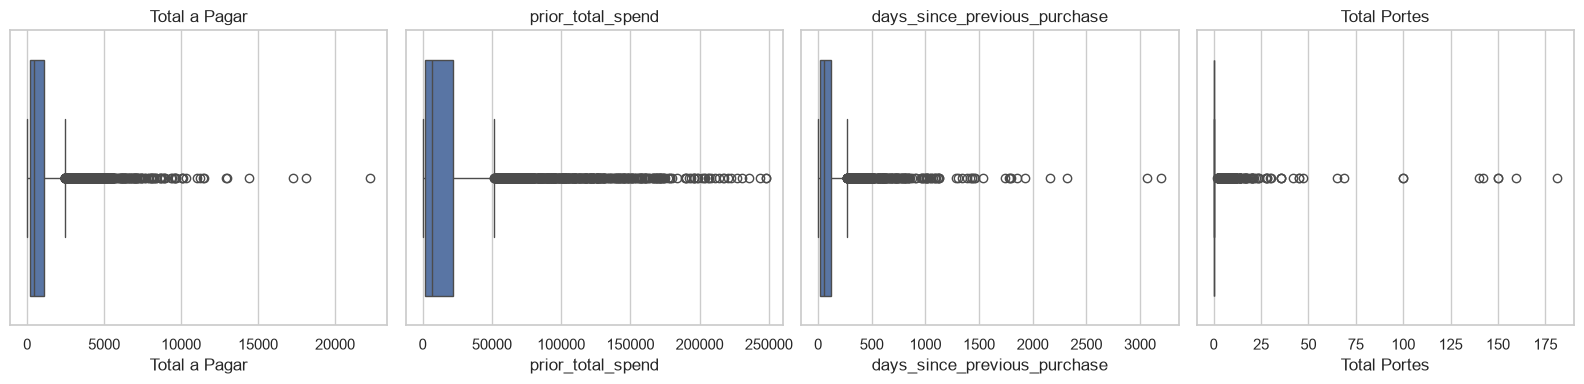

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["Total a Pagar", "prior_total_spend", "days_since_previous_purchase", "Total Portes"]):
    sns.boxplot(x=h[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [31]:
outliers = {}
for col in NUMERIC:
    q1 = h[col].quantile(0.25)
    q3 = h[col].quantile(0.75)
    iqr = q3 - q1
    outliers[col] = ((h[col] < q1 - 1.5 * iqr) | (h[col] > q3 + 1.5 * iqr)).sum()

pd.Series(outliers).sort_values(ascending=False)

spend_30d                         1060
Total Portes                      1053
Total Desc_ Linha                  822
purchase_count_180d                737
prior_min_purchase_value           671
spend_90d                          661
prior_total_spend                  642
Total a Pagar                      592
Total Liquido                      587
Total Bruto                        584
Custo                              539
Total Imp_                         533
purchase_count_365d                511
spend_180d                         508
purchase_count_90d                 502
prior_purchase_count               500
prior_std_gap_days                 461
spend_365d                         450
N_ Detalhes                        436
purchase_count_30d                 399
prior_mean_purchase_value          380
days_since_previous_purchase       377
prior_mean_gap_days                366
invoice_count_current_purchase     353
prior_max_purchase_value           299
prior_std_purchase_value 

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Most amount columns have <b>a lot of IQR outliers</b> (e.g. 592 for Total a Pagar), which fits the strong skew from 4.1</li>
  <li>For columns that are <b>mostly zero</b> (Total Portes, Total Desc_ Global) Q1 and Q3 are both 0, so <b>every value above 0</b> counts as an outlier --> the IQR rule does not work</li>
  <li>customer_tenure_days is the only column with <b>no outliers</b></li>
  <li>The high values look like <b>real big purchases</b> and not errors. Dropping them would remove about 9% of the rows for Total a Pagar alone --> in Task 2 we rather use a <b>log transform</b> than drop rows</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.7 ID columns and random_noise</h3>

</div>

In [32]:
for col in ["ID", "customer_id", "random_noise"]:
    print(col, "AUC:", round(roc_auc_score(tr[TARGET], tr[col]), 3))

ID AUC: 0.507
customer_id AUC: 0.433
random_noise AUC: 0.495


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>ID and random_noise have an AUC of <b>about 0.5</b> --> they have <b>no signal</b> at all</li>
  <li>customer_id has an AUC of <b>0.43</b>, so a bit of signal, but the number itself means nothing. The model would just <b>remember single customers</b> instead of learning something general</li>
  <li>So we use customer_id only to <b>join clientes.csv</b> and to <b>group the split</b>, but <b>not as a feature</b></li>
</ul>

</div>

<a id="clientes"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. clientes.csv</h2>

</div>

In [33]:
print("duplicated customer_id:", clientes["customer_id"].duplicated().sum())
print("train customers found in clientes:", train["customer_id"].drop_duplicates().isin(clientes["customer_id"]).mean())

pd.DataFrame({"levels": clientes.nunique(), "% missing": (100 * clientes.isna().mean()).round(1)})

duplicated customer_id: 0
train customers found in clientes: 1.0


,levels,% missing
customer_id,1143,0.0
country_or_region,11,0.0
commercial_region,37,10.0
island,10,50.6
municipality,183,13.9
city,417,47.8
postal_area,271,6.2
postal_code,828,14.9
street,511,52.3
address,1120,0.5


In [34]:
cl = tr.merge(clientes, on="customer_id", how="left")
print(cl.shape)

print(cl.groupby("country_or_region")[TARGET].mean().round(3))
print(cl["country_or_region"].value_counts())

(6469, 51)
country_or_region
Country CT10: Land of The Final Version    0.566
Country CT4: Land of The Final Version     0.000
Country CT5: Land of The Final Version     0.392
Country CT6: Land of The Final Version     0.500
Country CT7: Land of The Final Version     0.375
Country CT8: Land of The Final Version     0.000
Country CT9: Land of The Final Version     0.000
Name: repeat_purchase_90d, dtype: float64
country_or_region
Country CT10: Land of The Final Version    6256
Country CT5: Land of The Final Version      194
Country CT7: Land of The Final Version        8
Country CT6: Land of The Final Version        8
Country CT9: Land of The Final Version        1
Country CT8: Land of The Final Version        1
Country CT4: Land of The Final Version        1
Name: count, dtype: int64


In [35]:
cl["island_known"] = cl["island"].notna()
print(cl.groupby("island_known")[TARGET].mean().round(3))

print(clientes["customer_since_year"].value_counts().sort_index())

island_known
False    0.641
True     0.518
Name: repeat_purchase_90d, dtype: float64
customer_since_year
2015    664
2016     53
2017     82
2018     61
2019     47
2020     50
2021     52
2022     43
2023     29
2024     31
2025     18
2026     13
Name: count, dtype: int64


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li><b>Every customer</b> from train is in clientes and customer_id is <b>unique</b> --> the join does not add or lose any rows</li>
  <li>customer_type is <b>completely empty</b></li>  <li>company_name and address are different for almost every customer, so they work like <b>IDs</b> and are not useful</li>
  <li>city, street and island are about <b>50% missing</b>, and postal_code has <b>828 levels for 1,143 customers</b> --> far too many to be useful</li>
  <li>customer_since_year is <b>2015 for 58%</b> of the customers, which is the first year of the data. So 2015 probably means "2015 or earlier" --> customer_tenure_days is more exact</li>
  <li>Worth testing in Task 2: <b>country_or_region</b> (CT5 repeats 39% vs 57% for CT10) and <b>whether island is known</b> (64% if missing vs 52%)</li>
</ul>

</div>

<a id="uni"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>7. Univariate distributions</h2>

<p>The amounts are very skewed --> we plot them with log(1 + x)</p>

</div>

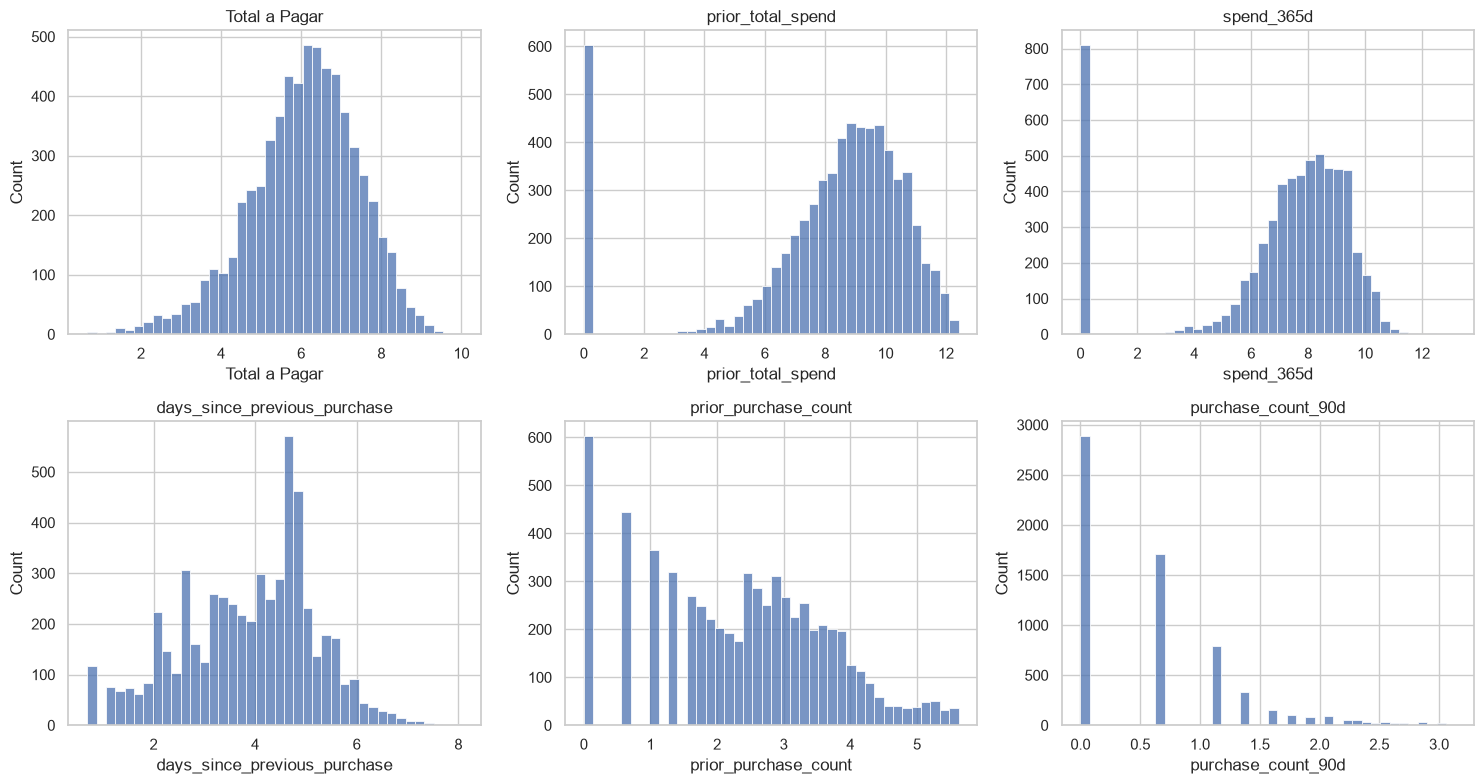

In [36]:
plot_cols = ["Total a Pagar", "prior_total_spend", "spend_365d",
             "days_since_previous_purchase", "prior_purchase_count", "purchase_count_90d"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), plot_cols):
    sns.histplot(np.log1p(h[col].dropna()), bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

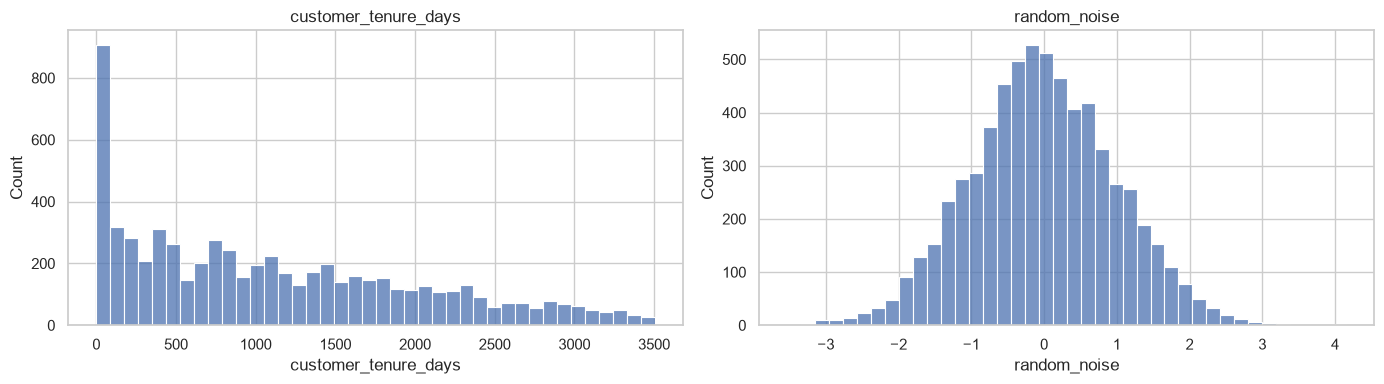

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(h["customer_tenure_days"], bins=40, ax=axes[0])
axes[0].set_title("customer_tenure_days")
sns.histplot(tr["random_noise"], bins=40, ax=axes[1])
axes[1].set_title("random_noise")
plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>With the log the amounts are <b>much more symmetric</b> (Total a Pagar looks almost like a bell curve) --> a <b>log transform</b> makes sense</li>
  <li>prior_purchase_count, prior_total_spend, spend_365d, purchase_count_90d and customer_tenure_days have a <b>separate peak at 0</b> --> these are first purchases or customers without a purchase in the time window --> they are <b>their own group</b></li>
  <li>days_since_previous_purchase has <b>two peaks</b>, a smaller one around 2–3 weeks and a big one around 100 days --> maybe two types of customers</li>
  <li>Apart from the peak at 0, customer_tenure_days is spread over the whole period and <b>not very skewed</b>, so it does not need a log</li>
  <li>random_noise is a <b>normal bell curve around 0</b></li>
</ul>

</div>

<a id="bi"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>8. Relationship with the target</h2>

<h3>8.1 Numeric features</h3>

<p>For each numeric feature we calculate the AUC on its own to see which features separate repeat and no repeat best</p>

</div>

In [38]:
auc = {}
for col in NUMERIC + ["random_noise"]:
    not_missing = h[col].notna()
    auc[col] = roc_auc_score(h.loc[not_missing, TARGET], h.loc[not_missing, col])

auc = pd.Series(auc)
auc_table = pd.DataFrame({"AUC": auc, "distance from 0.5": (auc - 0.5).abs()})
auc_table.sort_values("distance from 0.5", ascending=False).round(3)

,AUC,distance from 0.5
purchase_count_365d,0.753,0.253
prior_mean_gap_days,0.252,0.248
purchase_count_180d,0.732,0.232
spend_365d,0.725,0.225
purchase_count_90d,0.716,0.216
spend_180d,0.714,0.214
prior_purchase_count,0.701,0.201
spend_90d,0.699,0.199
prior_total_spend,0.693,0.193
prior_std_gap_days,0.313,0.187


In [39]:
# median of the top features for repeat vs no repeat
top = ["purchase_count_365d", "prior_mean_gap_days", "days_since_previous_purchase", "spend_365d", "Total a Pagar"]
h.groupby(TARGET)[top].median()

,purchase_count_365d,prior_mean_gap_days,days_since_previous_purchase,spend_365d,Total a Pagar
repeat_purchase_90d,,,,,
0,2.0,101.750000,105.0,1150.16,443.12
1,5.0,55.757576,37.0,4544.38,517.46


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>The strongest feature is <b>purchase_count_365d</b> (AUC 0.75) --> customers who repeat had <b>5 purchases</b> in the last year (median), the others only <b>2</b></li>
  <li>spend_365d is also strong (AUC 0.73) --> customers who repeat spent about <b>4,544</b> in the last year (median), the others only <b>1,150</b></li>
  <li>prior_mean_gap_days has an AUC of <b>0.25</b>, which is far below 0.5 --> it is also a <b>strong feature</b>, just the other way round</li>
  <li><b>Short gaps</b> between purchases (56 vs 102 days) and a <b>recent last purchase</b> (37 vs 105 days) mean more repeats</li>
  <li>The amounts of the current invoice are all <b>around 0.5</b> --> what someone buys now says <b>almost nothing</b> about coming back. Only the line discount is a bit higher (0.61)</li>
  <li>random_noise is at <b>0.495</b> --> features close to this are not useful</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>8.2 Repeat rate by recency and frequency</h3>

</div>

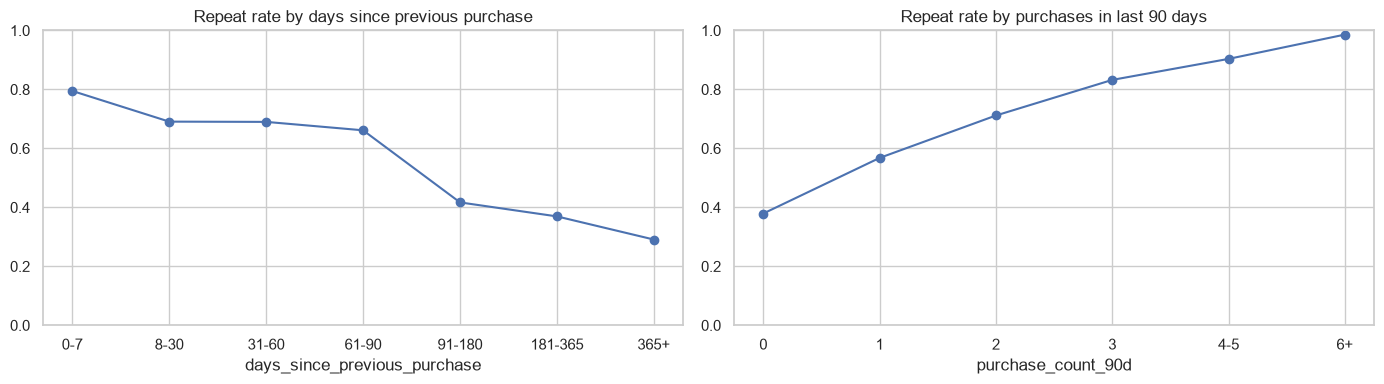

In [40]:
recency_bins = pd.cut(h["days_since_previous_purchase"], [0, 7, 30, 60, 90, 180, 365, 5000],
                      labels=["0-7", "8-30", "31-60", "61-90", "91-180", "181-365", "365+"], include_lowest=True)
frequency_bins = pd.cut(h["purchase_count_90d"], [-1, 0, 1, 2, 3, 5, 100], labels=["0", "1", "2", "3", "4-5", "6+"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
h.groupby(recency_bins, observed=True)[TARGET].mean().plot(marker="o", ax=axes[0])
axes[0].set_title("Repeat rate by days since previous purchase")
axes[0].set_ylim(0, 1)
h.groupby(frequency_bins, observed=True)[TARGET].mean().plot(marker="o", ax=axes[1])
axes[1].set_title("Repeat rate by purchases in last 90 days")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [41]:
print(h.groupby(recency_bins, observed=True)[TARGET].mean().round(2))
print(h.groupby(frequency_bins, observed=True)[TARGET].mean().round(2))

days_since_previous_purchase
0-7        0.79
8-30       0.69
31-60      0.69
61-90      0.66
91-180     0.42
181-365    0.37
365+       0.29
Name: repeat_purchase_90d, dtype: float64
purchase_count_90d
0      0.38
1      0.57
2      0.71
3      0.83
4-5    0.90
6+     0.99
Name: repeat_purchase_90d, dtype: float64


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Up to <b>90 days</b> since the last purchase the repeat rate stays high (<b>0.66 to 0.79</b>). After 90 days it <b>drops</b> to 0.42 and goes down to 0.29 --> this fits the 90 day definition of the target</li>
  <li>The <b>more purchases</b> in the last 90 days, the <b>higher the repeat rate</b> --> from 0.38 with no purchase up to <b>0.99</b> with 6 or more</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>8.3 Categorical features</h3>

<p>Chi square test and Cramér's V</p>

</div>

In [42]:
results = []
for col in CATEGORICAL:
    table = pd.crosstab(tr[col].fillna("missing"), tr[TARGET])
    chi2, p, dof, expected = chi2_contingency(table)
    v = association(table, method="cramer")
    results.append({"feature": col, "levels": table.shape[0], "p-value": round(p, 3), "Cramer's V": round(v, 3)})

pd.DataFrame(results).sort_values("Cramer's V", ascending=False)

,feature,levels,p-value,Cramer's V
3,transport_method,81,0.000,0.285
0,payment_type,10,0.000,0.234
1,salesperson,10,0.000,0.201
2,commercial_zone,5,0.000,0.064
4,warehouse,3,0.006,0.040
5,document_series,3,0.973,0.003


In [43]:
# repeat rate and rows per level
for col in ["payment_type", "salesperson"]:
    rate = tr.groupby(col)[TARGET].mean().round(2)
    counts = tr[col].value_counts()
    print(pd.DataFrame({"repeat rate": rate, "rows": counts}).sort_values("rows", ascending=False), "\n")

                           repeat rate  rows
payment_type                                
Maybe Tomorrow Payment 7          0.53  4565
Maybe Tomorrow Payment 12         0.54   991
Maybe Tomorrow Payment 9          0.95   502
Maybe Tomorrow Payment 10         0.40   134
Maybe Tomorrow Payment 8          0.32    40
Maybe Tomorrow Payment 2          0.52    21
Maybe Tomorrow Payment 4          0.44     9
Maybe Tomorrow Payment 11         0.62     8
Maybe Tomorrow Payment 3          0.50     4 

                  repeat rate  rows
salesperson                        
VLOOKUP Master 1         0.62  4054
VLOOKUP Master 4         0.39  1461
VLOOKUP Master 9         0.55   384
VLOOKUP Master 7         0.48   201
VLOOKUP Master 2         0.60   123
VLOOKUP Master 3         0.37    30
VLOOKUP Master 6         0.00    12
VLOOKUP Master 5         0.43     7
VLOOKUP Master 8         1.00     3 



In [44]:
# is Payment 9 only high because these customers buy very often?
frequency_group = pd.cut(tr["purchase_count_90d"], [-1, 0, 2, 100], labels=["0", "1-2", "3+"])

# repeat rate per payment type and group
pd.crosstab(tr["payment_type"], frequency_group, values=tr[TARGET], aggfunc="mean").round(2)

purchase_count_90d,0,1-2,3+
payment_type,,,
Maybe Tomorrow Payment 10,0.40,0.42,0.00
Maybe Tomorrow Payment 11,0.67,0.60,NaN
Maybe Tomorrow Payment 12,0.34,0.57,0.93
Maybe Tomorrow Payment 2,0.75,0.22,NaN
Maybe Tomorrow Payment 3,0.67,0.00,NaN
Maybe Tomorrow Payment 4,0.50,0.33,NaN
Maybe Tomorrow Payment 7,0.38,0.62,0.85
Maybe Tomorrow Payment 8,0.34,0.30,0.00
Maybe Tomorrow Payment 9,0.48,0.85,0.99


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li><b>payment_type</b> (0.23) and <b>salesperson</b> (0.20) have the strongest link. transport_method looks stronger (0.29), but with <b>81 levels</b> this is too high --> we have to group the rare levels first</li>
  <li>commercial_zone and warehouse are <b>weak</b> (almost constant), document_series has <b>no link</b> (p = 0.97)</li>
  <li>Salesperson: <b>Master 1 repeats 62%</b>, <b>Master 4 only 39%</b>. Levels with very few rows (e.g. Master 8 with 3 rows) are <b>not reliable</b></li>
  <li>Payment 9 repeats <b>95%</b> vs 53% for Payment 7, but with the same number of purchases the gap gets <b>much smaller</b> (0.99 vs 0.85 with 3+) --> for the big payment types <b>how often someone buys</b> matters more than how they pay</li>
</ul>

</div>

<a id="multi"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>9. Multivariate relationships</h2>

<h3>9.1 Correlation</h3>

<p>We use Spearman because the columns are skewed and have outliers</p>

</div>

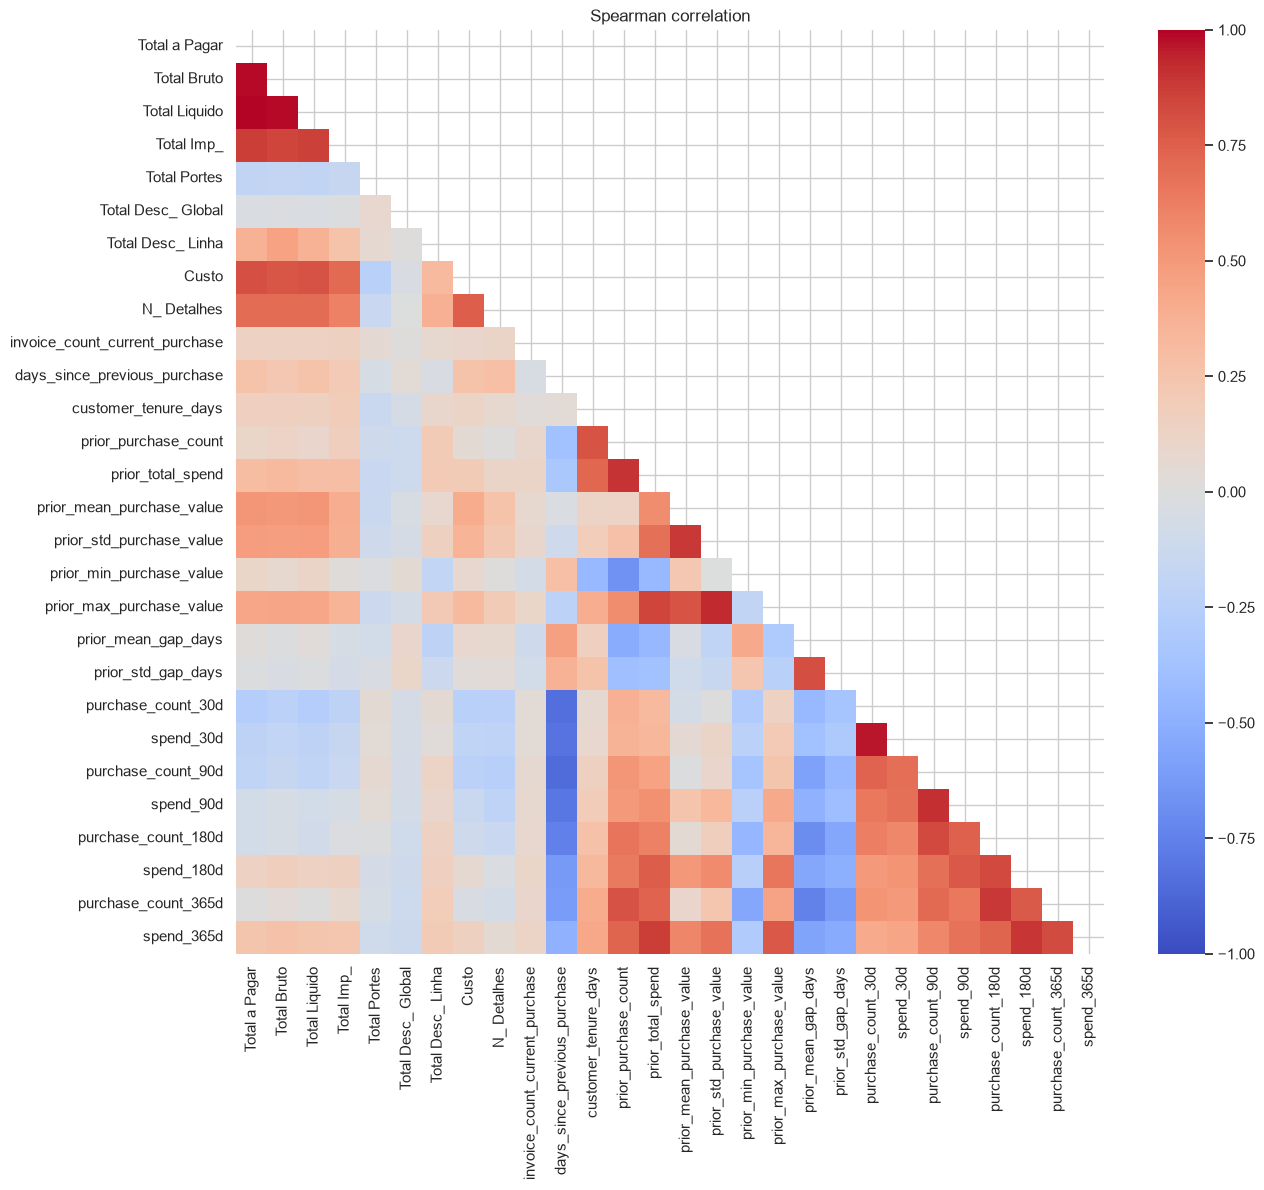

In [45]:
corr = h[NUMERIC].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Spearman correlation")
plt.show()

In [46]:
# pairs with a very high correlation
for i in range(len(NUMERIC)):
    for j in range(i + 1, len(NUMERIC)):
        value = corr.iloc[i, j]
        if abs(value) >= 0.85:
            print(NUMERIC[i], "-", NUMERIC[j], round(value, 2))

Total a Pagar - Total Bruto 0.99
Total a Pagar - Total Liquido 1.0
Total a Pagar - Total Imp_ 0.87
Total Bruto - Total Liquido 0.99
Total Liquido - Total Imp_ 0.86
days_since_previous_purchase - purchase_count_90d -0.86
prior_purchase_count - prior_total_spend 0.9
prior_total_spend - spend_365d 0.87
prior_mean_purchase_value - prior_std_purchase_value 0.88
prior_std_purchase_value - prior_max_purchase_value 0.92
purchase_count_30d - spend_30d 0.97
purchase_count_90d - spend_90d 0.91
purchase_count_180d - purchase_count_365d 0.89
spend_180d - spend_365d 0.89


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Total a Pagar, Total Liquido and Total Bruto are <b>almost the same</b> (0.99 to 1.00), and Total Imp_ is also very close (0.86 to 0.87)</li>
  <li>Count and spend go together in the <b>30 and 90 day windows</b> (0.97 and 0.91), and the <b>180 and 365 day windows</b> are also very similar (0.89)</li>
  <li>The history columns are linked too, e.g. prior_purchase_count and prior_total_spend (0.90) or prior_std and prior_max_purchase_value (0.92)</li>
  <li>days_since_previous_purchase and purchase_count_90d are <b>strongly negative</b> (-0.86) --> they measure the same thing from two sides</li>
  <li>So many features are <b>redundant</b> --> in Task 3 we can keep one per group</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>9.2 Recency and frequency together</h3>

</div>

In [47]:
recency_group = pd.cut(h["days_since_previous_purchase"], [0, 30, 90, 180, 5000],
                       labels=["0-30", "31-90", "91-180", "180+"], include_lowest=True)
frequency_group = pd.cut(h["purchase_count_365d"], [-1, 1, 3, 7, 15, 100], labels=["0-1", "2-3", "4-7", "8-15", "16+"])
pd.crosstab(recency_group, frequency_group, values=h[TARGET], aggfunc="mean").round(2)

purchase_count_365d,0-1,2-3,4-7,8-15,16+
days_since_previous_purchase,,,,,
0-30,0.42,0.44,0.64,0.87,0.99
31-90,0.46,0.52,0.70,0.90,0.93
91-180,0.34,0.33,0.53,0.79,1.00
180+,0.28,0.44,0.62,1.00,NaN


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>With the <b>same recency</b> the frequency changes the rate <b>a lot</b></li>
  <li>With the <b>same frequency</b> the recency changes <b>much less</b> --> a big part of the recency effect is <b>really frequency</b></li>
  <li>There is <b>no customer</b> in the data with 16+ purchases a year whose last purchase was more than 180 days ago (NaN) --> another sign that the two are <b>strongly linked</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>9.3 Customers with many rows</h3>

</div>

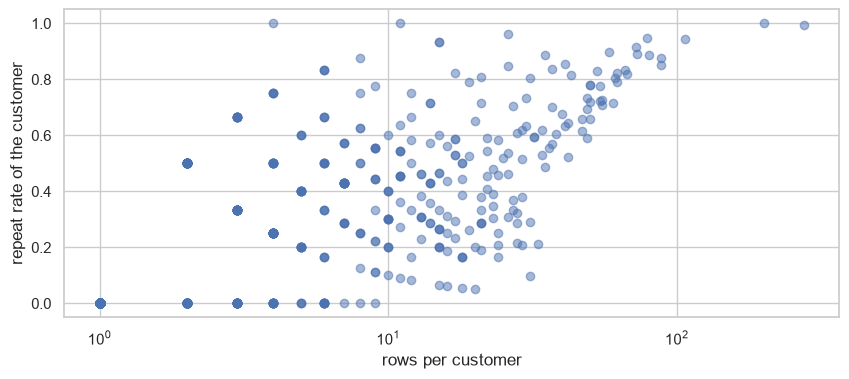

repeat rate of customers with only 1 row: 0.0


In [48]:
# repeat rate and number of rows per customer
customer_rate = tr.groupby("customer_id")[TARGET].mean()
customer_rows = tr.groupby("customer_id").size()

# one point = one customer
plt.figure(figsize=(10, 4))
plt.scatter(customer_rows, customer_rate, alpha=0.5)
plt.xscale("log")
plt.xlabel("rows per customer")
plt.ylabel("repeat rate of the customer")
plt.show()

print("repeat rate of customers with only 1 row:", customer_rate[customer_rows == 1].mean())

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>Customers with <b>many rows almost always repeat</b>, customers with <b>only one row never do</b> (0.0) --> if they had bought again, there would be a second row</li>
  <li>So the target depends a lot on <b>who the customer is</b> --> if the same customer is in train and validation, the model can just recognise him and the score looks <b>too good</b></li>
<li>For Task 4 we should <b>not split randomly</b> --> a <b>time split</b> is better, because then the model only learns from the past of a customer</li>
</ul>

</div>

<a id="time"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>10. Changes over time</h2>

</div>

In [49]:
# split the years into 3 periods
period = pd.cut(tr["purchase_date"].dt.year, [2014, 2018, 2021, 2025], labels=["2015-2018", "2019-2021", "2022-2025"])

compare = ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
           "purchase_count_90d", "purchase_count_365d", "Total a Pagar"]
print(h[compare].groupby(period, observed=True).median().T)
print(tr.groupby(period, observed=True)[TARGET].mean().round(3))

purchase_date         2015-2018  2019-2021  2022-2025
customer_tenure_days     309.00    1119.00   1918.000
prior_purchase_count       4.00      14.00     20.000
prior_total_spend       2275.79    8205.47  14094.630
purchase_count_90d         1.00       1.00      1.000
purchase_count_365d        3.00       4.00      4.000
Total a Pagar            382.06     450.07    620.285
purchase_date
2015-2018    0.562
2019-2021    0.555
2022-2025    0.562
Name: repeat_purchase_90d, dtype: float64


In [50]:
# document series per year
pd.crosstab(tr["purchase_date"].dt.year, tr["document_series"])

document_series,Ctrl Z Series 1,Ctrl Z Series 2,Ctrl Z Series 3
purchase_date,,,
2015,0,0,335
2016,0,0,420
2017,281,0,389
2018,387,0,329
2019,397,0,249
2020,532,0,138
2021,231,508,43
2022,0,628,0
2023,0,767,0


In [51]:
# share of each salesperson per period
pd.crosstab(tr["salesperson"], period, normalize="columns").round(2)

purchase_date,2015-2018,2019-2021,2022-2025
salesperson,,,
VLOOKUP Master 1,0.75,0.65,0.54
VLOOKUP Master 2,0.06,0.00,0.00
VLOOKUP Master 3,0.01,0.00,0.00
VLOOKUP Master 4,0.08,0.34,0.28
VLOOKUP Master 5,0.00,0.00,0.00
VLOOKUP Master 6,0.00,0.01,0.00
VLOOKUP Master 7,0.09,0.01,0.00
VLOOKUP Master 8,0.00,0.00,0.00
VLOOKUP Master 9,0.00,0.00,0.18


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insights</b></p>
<ul>
  <li>The repeat rate is the <b>same in all periods</b> (about 0.56)</li>
  <li>Tenure, earlier purchases, total spend and also the purchase amount <b>grow over time</b>, while the window features (90/365 days) stay <b>stable</b> --> they should work better on later data</li>
  <li>document_series only shows the <b>time period</b> and has no link with the target --> <b>we drop it</b></li>
  <li>Some salesperson levels <b>appear or disappear</b> (e.g. Master 9 only from 2022) --> in Task 2 the encoder must handle unknown levels</li>
</ul>

</div>

<a id="summary"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>11. Summary and next steps</h2>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Summary</b></p>

<table>
  <tr><th>What we found</th><th>What we do</th><th>Task</th></tr>
  <tr><td>65 rows are completely empty</td><td><b>drop</b> them</td><td>2</td></tr>
  <tr><td>Some values are impossible (1,000,000,000, negative amounts, -4 days) or wrong (46 means)</td><td>set them to <b>NaN</b>, then <b>recompute</b> or fill them</td><td>2</td></tr>
  <tr><td>First purchases have no history values and repeat only 33%</td><td>add a column that says <b>"first purchase: yes/no"</b></td><td>2</td></tr>
  <tr><td>The other missing values (~3%) look random</td><td>fill them with the <b>median or mode</b> (calculated only from train)</td><td>2</td></tr>
  <tr><td>Amounts are very skewed and have many outliers</td><td>use a <b>log transform</b> instead of dropping rows</td><td>2</td></tr>
  <tr><td>transport_method has 80 levels, and some levels only appear in some years</td><td><b>group rare levels</b> and use an encoder that can handle new levels</td><td>2</td></tr>
  <tr><td>In clientes.csv, country_or_region and whether the island is known show differences in the repeat rate</td><td><b>join</b> clientes.csv and <b>test</b> these two</td><td>2</td></tr>
  <tr><td>ID, random_noise and document_series have no link with the target</td><td><b>do not use</b> them as features</td><td>3</td></tr>
  <tr><td>Many features say almost the same (e.g. Total a Pagar, Liquido, Bruto)</td><td>keep only <b>one per group</b></td><td>3</td></tr>
  <tr><td>Purchases and spend in the last 90/365 days are the strongest features and stay stable over time</td><td>focus on these <b>window features</b></td><td>3</td></tr>
  <tr><td>Always predicting 1 is already right in 55.9% of the cases</td><td>use <b>other metrics</b> besides accuracy</td><td>4</td></tr>
  <tr><td>Rows of the same customer are not independent</td><td>split the data <b>by time</b>, not randomly</td><td>4</td></tr>
</table>

</div>